Imports and project setup

In [25]:

# Mini-Project 2: Solar Micro-Grid Dispatch Planner
# Notebook setup and imports

from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Make the project root available for imports.
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "src" / "solar_microgrid").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "src" / "solar_microgrid").exists():
    raise FileNotFoundError(
        "Could not locate src/solar_microgrid. "
        "Open the notebook from the project directory."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.solar_microgrid.microgrid import MicroGrid
from src.solar_microgrid.data_generator import generate_demand_data
from src.solar_microgrid.analysis import (
    solve_with_loop,
    solve_vectorised,
    compare_execution_times,
    summarise_usage,
    calculate_costs,
    handle_infeasible_days,
    plot_dispatch_and_cost,
    sensitivity_analysis,
)
from src.solar_microgrid.hybrid_microgrid import HybridMicroGrid

# print("Project root:", PROJECT_ROOT)
# print("NumPy version:", np.__version__)
# print("Pandas version:", pd.__version__)


2 - Load and inspect the data

In [26]:

# Cell 2: Load and inspect the 30-day demand dataset

DATA_PATH = PROJECT_ROOT / "data" / "microgrid_demand_30days.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)

print(f"Number of days: {len(df)}")
print(f"Number of columns: {len(df.columns)}")




Number of days: 30
Number of columns: 4


In [27]:
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five records:")
display(df.head())




Column names:
['day', 'day_of_week', 'D1_kwh', 'D2_kwh']

First five records:


,day,day_of_week,D1_kwh,D2_kwh
0,1,Monday,121.52,107.99
1,2,Tuesday,119.80,100.73
2,3,Wednesday,130.75,99.33
3,4,Thursday,130.70,96.69
4,5,Friday,114.24,99.90


In [28]:
print("\nDataset information:")
df.info()



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   day          30 non-null     int64  
 1   day_of_week  30 non-null     str    
 2   D1_kwh       30 non-null     float64
 3   D2_kwh       30 non-null     float64
dtypes: float64(2), int64(1), str(1)
memory usage: 1.3 KB


In [29]:

print("\nDescriptive statistics:")
display(df.describe())

print("\nMissing values per column:")
display(df.isna().sum())


Descriptive statistics:


,day,D1_kwh,D2_kwh
count,30.000000,30.000000,30.000000
mean,15.500000,122.117333,100.458333
std,8.803408,5.612402,2.695951
min,1.000000,110.490000,96.130000
25%,8.250000,117.602500,98.987500
50%,15.500000,121.790000,99.905000
75%,22.750000,126.920000,101.887500
max,30.000000,131.110000,107.990000



Missing values per column:


day            0
day_of_week    0
D1_kwh         0
D2_kwh         0
dtype: int64

Solve Daily Dispatch Using Two Methods.

we'll use existing MicroGrid class and the functions already implemented in analysis.py.

We'll calculate the solar and battery energy required for each of the 30 days using both a loop-based approach and a vectorized approach, then compare the results.

In [30]:

# Cell 3: Solve daily dispatch using loop-based and vectorized methods

grid = MicroGrid()

# Method 1: Solve each day individually
loop_results = solve_with_loop(grid, df)

# Method 2: Solve all days using vectorized linear algebra
vector_results = solve_vectorised(grid, df)

print("Loop-based results (first five days):")
display(loop_results.head())


Loop-based results (first five days):


,d1,d2,solar_kwh,battery_kwh,feasible
0,121.52,107.99,18.892,32.422,True
1,119.80,100.73,16.332,35.402,True
2,130.75,99.33,13.582,45.002,True
3,130.70,96.69,12.536,46.546,True
4,114.24,99.90,17.112,31.452,True


In [31]:

print("\nVectorized results (first five days):")
display(vector_results[["day", "solar_kwh", "battery_kwh", "feasible"]].head())



Vectorized results (first five days):


,day,solar_kwh,battery_kwh,feasible
0,1,18.892,32.422,True
1,2,16.332,35.402,True
2,3,13.582,45.002,True
3,4,12.536,46.546,True
4,5,17.112,31.452,True


In [32]:
# Compare the numerical solutions
solutions_agree = np.allclose(loop_results[["solar_kwh", "battery_kwh"]].to_numpy(), vector_results[["solar_kwh", "battery_kwh"]].to_numpy(),)

print("\nNumber of days solved using the loop:", len(loop_results))
print("Number of days solved using vectorization:", len(vector_results))
print("Do both methods produce matching energy solutions?", solutions_agree)

assert len(loop_results) == len(df), "Loop method did not solve every day."
assert len(vector_results) == len(df), "Vectorized method did not solve every day."
assert solutions_agree, "The two methods produced different energy solutions."



Number of days solved using the loop: 30
Number of days solved using vectorization: 30
Do both methods produce matching energy solutions? True


Loop-based computation: Python processes each day individually.

Vectorized computation: NumPy and SciPy solve the demand equations for multiple days in a single matrix operation.

Numerical verification: np.allclose() checks whether both methods return approximately equal results, allowing for minor floating-point differences.


Performance Comparison.

we'll measure how long the loop-based and vectorized methods take to solve the same 30-day dispatch problem.

In [33]:

# Cell 4: Compare loop-based and vectorized execution times

timing_results = compare_execution_times(grid=grid, demands=df, number=1000,)
loop_time = timing_results["loop_seconds_per_run"]
vector_time = timing_results["vectorised_seconds_per_run"]

print("AVERAGE EXECUTION TIME")
print("-" * 40)
print(f"Loop-based method:     {loop_time:.8f} seconds")
print(f"Vectorized method:     {vector_time:.8f} seconds")


AVERAGE EXECUTION TIME
----------------------------------------
Loop-based method:     0.00227500 seconds
Vectorized method:     0.00155030 seconds


In [34]:
if vector_time > 0:
    speedup = loop_time / vector_time
    print(f"\nSpeedup ratio:         {speedup:.2f}x")

    if speedup > 1:
        print("The vectorized method was faster in this benchmark.")
    elif speedup < 1:
        print("The loop-based method was faster in this benchmark.")
    else:
        print("Both methods had approximately equal execution times.")
else:
    print("\nThe vectorized execution time was too small to calculate a ratio.")

print("\nEach reported time is the average per run across 1,000 repetitions.")



Speedup ratio:         1.47x
The vectorized method was faster in this benchmark.

Each reported time is the average per run across 1,000 repetitions.


Descriptive Statistics and Energy Costs in UGX.

we'll summarize solar and battery usage and calculate daily and total costs using your existing rates of UGX 150 per kWh for solar and UGX 450 per kWh for battery energy.

In [35]:

# Cell 5A: Descriptive statistics for solar and battery usage

usage_summary = summarise_usage(vector_results)

print("DESCRIPTIVE STATISTICS OF ENERGY DISPATCH")
print("Values are measured in kWh.")
display(usage_summary.round(3))


DESCRIPTIVE STATISTICS OF ENERGY DISPATCH
Values are measured in kWh.


,solar_kwh,battery_kwh
mean,15.760,37.419
var,2.685,24.346
std,1.638,4.934


Calculate daily and total costs

In [36]:

# Cell 5B: Calculate daily and total energy costs

cost_results = calculate_costs(vector_results)

print("DAILY ENERGY COSTS")
display(
    cost_results[
        ["day", "solar_cost_ugx", "battery_cost_ugx", "daily_cost_ugx"]
    ].round(2)
)

total_solar_cost = cost_results["solar_cost_ugx"].sum()
total_battery_cost = cost_results["battery_cost_ugx"].sum()
total_cost = cost_results["daily_cost_ugx"].sum()

print("\n30-DAY COST SUMMARY")
print("-" * 35)
print(f"Total solar cost:   UGX {total_solar_cost:,.2f}")
print(f"Total battery cost: UGX {total_battery_cost:,.2f}")
print(f"Total energy cost:  UGX {total_cost:,.2f}")
print(f"Average daily cost: UGX {cost_results['daily_cost_ugx'].mean():,.2f}")


DAILY ENERGY COSTS


,day,solar_cost_ugx,battery_cost_ugx,daily_cost_ugx
0,1,2833.8,14589.9,17423.7
1,2,2449.8,15930.9,18380.7
2,3,2037.3,20250.9,22288.2
3,4,1880.4,20945.7,22826.1
4,5,2566.8,14153.4,16720.2
5,6,2794.5,12285.0,15079.5
6,7,2510.4,14722.2,17232.6
7,8,2389.8,15890.4,18280.2
8,9,2221.2,18111.6,20332.8
9,10,2487.3,16421.4,18908.7



30-DAY COST SUMMARY
-----------------------------------
Total solar cost:   UGX 70,919.40
Total battery cost: UGX 505,154.70
Total energy cost:  UGX 576,074.10
Average daily cost: UGX 19,202.47


These are illustrative costs calculated from your assigned rates and modelled energy outputs.

Identify and Handle Infeasible Dispatch Days.

MicroGrid model solves the demand equations exactly, but some solutions can produce negative solar or battery energy.

Those solutions are mathematically valid but physically infeasible.

existing handle_infeasible_days() function uses non-negative least squares (NNLS) to find the closest non-negative alternative.

In [37]:

# Cell 6A: Identify physically infeasible dispatch days

infeasible_days = vector_results.loc[
    ~vector_results["feasible"]
].copy()

print("Number of days analysed:", len(vector_results))
print("Number of feasible days:", vector_results["feasible"].sum())
print("Number of infeasible days:", len(infeasible_days))

if infeasible_days.empty:
    print("\nAll days have non-negative solar and battery solutions.")
else:
    print("\nInfeasible dispatch days:")
    display(
        infeasible_days[
            ["day", "D1_kwh", "D2_kwh", "solar_kwh", "battery_kwh", "feasible"]
        ].round(3)
    )


Number of days analysed: 30
Number of feasible days: 30
Number of infeasible days: 0

All days have non-negative solar and battery solutions.


Apply non-negative least squares

In [38]:

# Cell 6B: Adjust infeasible dispatch using NNLS

handled_results = handle_infeasible_days(grid, vector_results)

print("Dispatch adjustment summary:")
print(
    handled_results["adjustment_method"]
    .value_counts()
    .to_string()
)

print("\nOriginal and adjusted dispatch:")
display(
    handled_results[
        [
            "day",
            "solar_kwh",
            "battery_kwh",
            "adjusted_solar_kwh",
            "adjusted_battery_kwh",
            "feasible",
            "adjustment_method",
        ]
    ].round(3)
)

# Verify that adjusted energy supplies are non-negative.
assert (handled_results["adjusted_solar_kwh"] >= -1e-10).all()
assert (handled_results["adjusted_battery_kwh"] >= -1e-10).all()

print("\nAll adjusted solar and battery values are non-negative.")


Dispatch adjustment summary:
adjustment_method
Exact solution    30

Original and adjusted dispatch:


,day,solar_kwh,battery_kwh,adjusted_solar_kwh,adjusted_battery_kwh,feasible,adjustment_method
0,1,18.892,32.422,18.892,32.422,True,Exact solution
1,2,16.332,35.402,16.332,35.402,True,Exact solution
2,3,13.582,45.002,13.582,45.002,True,Exact solution
3,4,12.536,46.546,12.536,46.546,True,Exact solution
4,5,17.112,31.452,17.112,31.452,True,Exact solution
5,6,18.630,27.300,18.630,27.300,True,Exact solution
6,7,16.736,32.716,16.736,32.716,True,Exact solution
7,8,15.932,35.312,15.932,35.312,True,Exact solution
8,9,14.808,40.248,14.808,40.248,True,Exact solution
9,10,16.582,36.492,16.582,36.492,True,Exact solution



All adjusted solar and battery values are non-negative.


Key Take aways

- Original solution: satisfies the two demand equations exactly, when the coefficient matrix is nonsingular.
- Infeasible solution: may require negative energy from one source, which is not physically possible.
- NNLS solution: finds non-negative source values that minimize the mismatch with the original demand equations. It does not necessarily satisfy both equations exactly.

Visualize Daily Dispatch and Energy Costs.

We'll use existing plot_dispatch_and_cost() function from analysis.py.



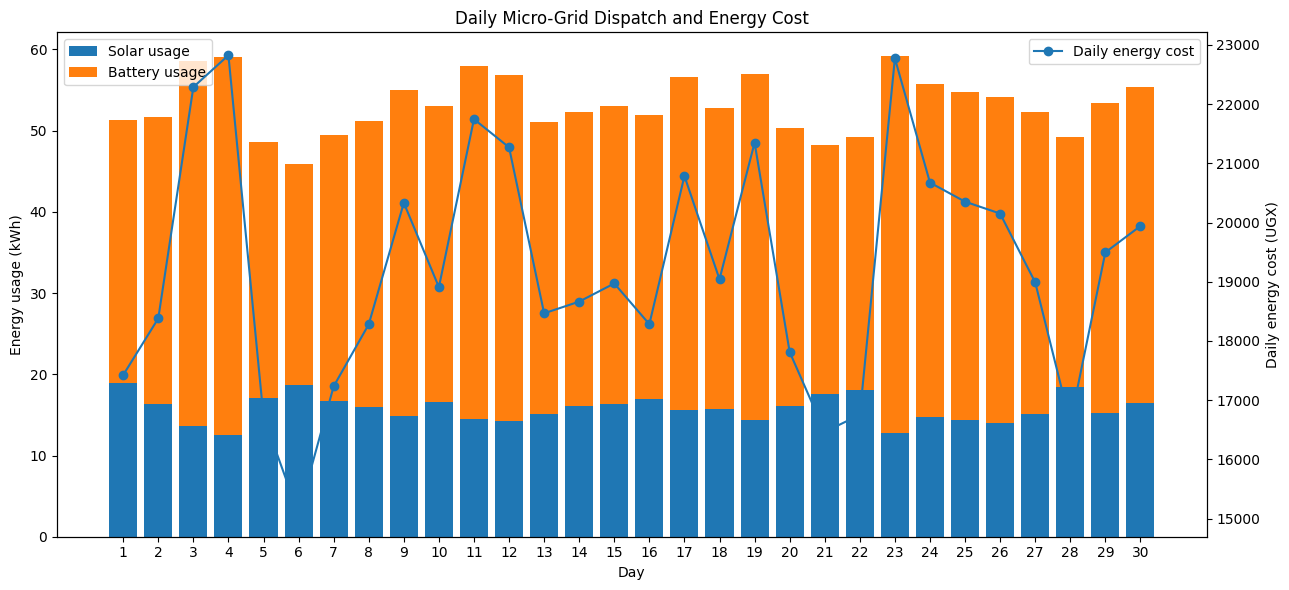

In [39]:

# Cell 7: Visualize daily dispatch and energy costs

# Calculate costs for the dispatch results
plot_results = calculate_costs(vector_results)

# Display the stacked energy dispatch and daily cost chart
plot_dispatch_and_cost(plot_results)


* Stacked bars: Daily solar and battery energy usage in kWh.
* Line: Daily energy cost in UGX.
* Horizontal axis: Days 1-30.

note:The chart uses the exact dispatch solutions. If some days have negative energy values, the visualization may show them below zero. That is useful for identifying infeasibility, but it means the chart should not be interpreted as a fully physically feasible operating schedule.

Sensitivity Analysis,

This section will show how changes of ±5% in daily demand affect the solar and battery dispatch requirements across 1,000 simulations.

We'll use existing sensitivity_analysis() function, which we already tested successfully with seed 42.

In [40]:

# Cell 8A: Run sensitivity analysis

sensitivity_results = sensitivity_analysis(
    grid=grid,
    demands=df,
    n_simulations=1000,
    seed=42,
)

print("SENSITIVITY ANALYSIS RESULTS")
print("-" * 45)

for metric, value in sensitivity_results.items():
    if isinstance(value, float):
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")


SENSITIVITY ANALYSIS RESULTS
---------------------------------------------
solar_mean_absolute_change_kwh: 1.1300
battery_mean_absolute_change_kwh: 2.7490
solar_max_absolute_change_kwh: 3.3678
battery_max_absolute_change_kwh: 8.1407
solar_95th_percentile_change_kwh: 2.5288
battery_95th_percentile_change_kwh: 6.1838
condition_number: 5.8284
n_simulations: 1000
seed: 42


In [41]:

# Cell 8B: Organize sensitivity metrics for interpretation

sensitivity_table = pd.DataFrame({
    "Metric": [
        "Mean absolute change",
        "Maximum absolute change",
        "95th-percentile absolute change",
    ],
    "Solar (kWh)": [
        sensitivity_results["solar_mean_absolute_change_kwh"],
        sensitivity_results["solar_max_absolute_change_kwh"],
        sensitivity_results["solar_95th_percentile_change_kwh"],
    ],
    "Battery (kWh)": [
        sensitivity_results["battery_mean_absolute_change_kwh"],
        sensitivity_results["battery_max_absolute_change_kwh"],
        sensitivity_results["battery_95th_percentile_change_kwh"],
    ],
})

display(sensitivity_table.round(3))

print(f"\nCondition number: {sensitivity_results['condition_number']:.4f}")
print(f"Number of simulations: {sensitivity_results['n_simulations']}")
print(f"Random seed: {sensitivity_results['seed']}")


,Metric,Solar (kWh),Battery (kWh)
0,Mean absolute change,1.130,2.749
1,Maximum absolute change,3.368,8.141
2,95th-percentile absolute change,2.529,6.184



Condition number: 5.8284
Number of simulations: 1000
Random seed: 42



### Sensitivity Analysis: Findings and Interpretation

The sensitivity analysis evaluates how independent demand variations of ±5% affect the calculated solar and battery dispatch requirements. A total of 1,000 simulations are conducted using a fixed random seed of 42 to support reproducibility.

The simulation results indicate that battery dispatch experiences a larger absolute change than solar dispatch. The mean absolute change is approximately 2.749 kWh for battery output and 1.130 kWh for solar output. The 95th-percentile absolute changes are approximately 6.184 kWh and 2.529 kWh, respectively.

These findings suggest that battery dispatch is more affected in absolute energy terms under the specified demand perturbations. However, absolute changes do not measure relative sensitivity, and the results depend on the model's coefficient matrix and assumptions. Because the analysis perturbs demand inputs independently and uses the linear dispatch equations, the findings should be interpreted as model-based sensitivity estimates rather than forecasts of actual micro-grid performance.


Hybrid Micro-Grid Analysis

This section extends the two-source model by introducing a third source: diesel generation.

In [42]:

# Cell 9A: Hybrid micro-grid dispatch

hybrid_grid = HybridMicroGrid()

# Illustrative demand constraints in kWh
D1 = 100.0
D2 = 80.0
D3 = 60.0

hybrid_result = hybrid_grid.solve_hybrid_day(D1, D2, D3)

print("HYBRID MICRO-GRID DISPATCH")
print("-" * 40)
print(f"Daytime demand constraint (D1): {D1:.2f} kWh")
print(f"Critical-equipment constraint (D2): {D2:.2f} kWh")
print(f"Total supply constraint (D3): {D3:.2f} kWh")

print(f"\nSolar generation:   {hybrid_result['solar_kwh']:.2f} kWh")
print(f"Battery supply:     {hybrid_result['battery_kwh']:.2f} kWh")
print(f"Diesel generation:  {hybrid_result['diesel_kwh']:.2f} kWh")
print(f"Dispatch feasible:  {hybrid_result['feasible']}")

print(f"\nDeterminant: {np.linalg.det(hybrid_grid.hybrid_coefficients):.4f}")
print(f"Condition number: {hybrid_grid.condition_number():.4f}")


HYBRID MICRO-GRID DISPATCH
----------------------------------------
Daytime demand constraint (D1): 100.00 kWh
Critical-equipment constraint (D2): 80.00 kWh
Total supply constraint (D3): 60.00 kWh

Solar generation:   12.00 kWh
Battery supply:     32.00 kWh
Diesel generation:  16.00 kWh
Dispatch feasible:  True

Determinant: -5.0000
Condition number: 7.7158


Compare the two-source and hybrid models

In [43]:

# Cell 9B: Compare model structures

comparison = pd.DataFrame({
    "Characteristic": [
        "Energy sources",
        "Number of equations",
        "Number of unknowns",
        "Coefficient matrix shape",
        "Condition number",
    ],
    "MicroGrid": [
        "Solar and battery",
        2,
        2,
        str(grid.coefficients.shape),
        grid.condition_number(),
    ],
    "HybridMicroGrid": [
        "Solar, battery and diesel",
        3,
        3,
        str(hybrid_grid.hybrid_coefficients.shape),
        hybrid_grid.condition_number(),
    ],
})

display(comparison)


,Characteristic,MicroGrid,HybridMicroGrid
0,Energy sources,Solar and battery,"Solar, battery and diesel"
1,Number of equations,2,3
2,Number of unknowns,2,3
3,Coefficient matrix shape,"(2, 2)","(3, 3)"
4,Condition number,5.828427,7.715758



### Hybrid Micro-Grid: Findings

The hybrid model extends the original two-source micro-grid by adding diesel generation as a third energy source. For the illustrative demand constraints D1 = 100 kWh, D2 = 80 kWh and D3 = 60 kWh, the model calculates solar generation of 12 kWh, battery supply of 32 kWh and diesel generation of 16 kWh.

The coefficient matrix has a non-zero determinant, indicating that the three equations have a unique solution for the specified demands. The calculated dispatch is feasible because all three energy-source values are non-negative.

This example demonstrates how object-oriented inheritance can extend an existing model while preserving its core functionality. However, the hybrid model remains a simplified mathematical representation. The results do not establish that a real health-centre micro-grid would operate optimally, because actual generation capacities, battery state of charge, conversion losses, fuel availability and operating constraints are not represented here.
